
---
date: "2026-10-24"
date-modified: last-modified
format:
  html:
    toc: true
---


# Numerical Integration

**Prerequisites:** [The Fundamental Theorem of Calculus](fundamental-theorem-of-calculus.ipynb#prp-variable-limits) · [Convexity, Inflection Points, and Curve Sketching](convexity-and-curve-sketching.ipynb) · [Local Extrema and the Mean Value Theorem](mean-value-theorem.ipynb)

Most integrals cannot be computed from an antiderivative, so they are approximated: cut $[a, b]$ into small pieces and replace $f$ on each piece by something easy to integrate.

## 1\. The Rules

Divide $[a, b]$ into $n$ equal parts of length $h = \frac{b - a}{n}$, with nodes $a_i = a + ih$ and midpoints $m_i = \frac{a_{i-1} + a_i}{2}$.

::: {#def-quadrature-rules}
## Left, Right, Midpoint, Trapezoid and Simpson Rules

$$\begin{aligned}
L(n) &= h\sum_{i=1}^n f(a_{i-1}), & R(n) &= h\sum_{i=1}^n f(a_i), & M(n) &= h\sum_{i=1}^n f(m_i),\\
T(n) &= h\sum_{i=1}^n \frac{f(a_{i-1}) + f(a_i)}{2}, & S(n) &= \frac{2M(n) + T(n)}{3} = \frac h6\sum_{i=1}^n\big(f(a_{i-1}) + 4f(m_i) + f(a_i)\big). &&
\end{aligned}$$
$T$ integrates the chords (trapezoids); $M$ uses the value at the midpoint, which equals the integral of the tangent line at the midpoint; $S$ integrates, on each piece, the parabola through the three points $a_{i-1}, m_i, a_i$.
:::

The last claim: for a quadratic $q$ on $[m - t, m + t]$, $\int q = \frac{t}{3}\big(q(m - t) + 4q(m) + q(m + t)\big)$ (check for $1$, $x - m$, $(x-m)^2$: both sides give $2t$, $0$, $\frac{2t^3}{3}$). In fact this also holds for $(x - m)^3$ (both sides $0$), so **Simpson's rule is exact for cubics**.

## 2\. Error Bounds

::: {#lem-integrate-bound}
## Integrating an Inequality

If $g$ is differentiable on $[0, T]$, $g(0) = 0$ and $|g'(t)| \le Ct^k$, then $|g(t)| \le \frac{C t^{k+1}}{k+1}$ on $[0, T]$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-integrate-bound
$\frac{Ct^{k+1}}{k+1} \mp g(t)$ vanish at $0$ and have derivatives $Ct^k \mp g'(t) \ge 0$, so they are increasing ([MVT](mean-value-theorem.ipynb#cor-mvt-consequences)), hence $\ge 0$. $\blacksquare$
:::

::: {#thm-left-right-error}
## Left and Right Rules

If $|f'| \le M_1$ on $[a, b]$, then $\big|\int_a^b f - L(n)\big| \le \frac{(b - a)M_1}{2}h$, and the same for $R(n)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-left-right-error
On a piece, $|f(x) - f(a_{i-1})| \le M_1(x - a_{i-1})$ by the MVT, so $\big|\int_{a_{i-1}}^{a_i}(f - f(a_{i-1}))\big| \le M_1\frac{h^2}{2}$. Summing $n$ pieces: $nM_1\frac{h^2}{2} = \frac{(b-a)M_1}{2}h$. $\blacksquare$
:::

::: {#prp-midpoint-trapezoid-order}
## Convex Functions: $M \le \int \le T$

If $f'' > 0$ on $[a, b]$, then $M(n) < \int_a^b f < T(n)$; if $f'' < 0$, the inequalities are reversed.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-midpoint-trapezoid-order
On each piece, the graph lies above the tangent at $m_i$ and below the chord ([convexity](convexity-and-curve-sketching.ipynb#prp-above-tangent), [chords](convexity-and-curve-sketching.ipynb#prp-chord-above)); integrate: the tangent line integrates to $hf(m_i)$ (the linear term is odd about $m_i$), the chord to $h\frac{f(a_{i-1}) + f(a_i)}{2}$. $\blacksquare$
:::

::: {#thm-trapezoid-midpoint-error}
## Trapezoid and Midpoint Rules

If $|f''| \le M_2$ on $[a, b]$, with $E_T = \int_a^b f - T(n)$ and $E_M = \int_a^b f - M(n)$:
$$|E_T| \le \frac{(b - a)M_2}{12}h^2, \qquad |E_M| \le \frac{(b - a)M_2}{24}h^2 .$$
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-trapezoid-midpoint-error
Fix a piece with midpoint $m$ and for $0 \le t \le \frac h2$ let
$$G(t) = \int_{m-t}^{m+t} f - t\big(f(m+t) + f(m-t)\big), \qquad H(t) = \int_{m-t}^{m+t} f - 2t f(m).$$
By the [FTC](fundamental-theorem-of-calculus.ipynb#prp-variable-limits), $\frac{d}{dt}\int_{m-t}^{m+t} f = f(m+t) + f(m-t)$, so
$$G'(t) = -t\big(f'(m+t) - f'(m-t)\big), \qquad H'(t) = f(m+t) + f(m-t) - 2f(m), \quad H''(t) = f'(m+t) - f'(m-t).$$
By the MVT, $|f'(m+t) - f'(m-t)| \le 2tM_2$. So $|G'| \le 2M_2t^2$ and $|G(t)| \le \frac23M_2t^3$; $|H''| \le 2M_2 t$, $H'(0) = 0$, so $|H'| \le M_2t^2$ and $|H(t)| \le \frac{M_2}{3}t^3$ (@lem-integrate-bound). At $t = \frac h2$ the errors on one piece are at most $\frac{M_2h^3}{12}$ and $\frac{M_2h^3}{24}$; multiply by $n = \frac{b-a}{h}$. $\blacksquare$
:::

The errors of $L, R$ involve $f'$ (how fast $f$ changes) and are of order $h$: ten times as many points give one more correct digit. Those of $T, M$ involve $f''$ (how curved the graph is) and are of order $h^2$: two more digits. For $f(x) = (x - m)^2$ on one piece, $E_M = \frac{2t^3}{3}$ and $E_T = -\frac{4t^3}{3} = -2E_M$; in general $E_T \approx -2E_M$, which is why $S = \frac{2M + T}{3}$ cancels the leading error.

::: {#thm-simpson-error}
## Simpson's Rule

If $|f^{(4)}| \le M_4$ on $[a, b]$, then $\displaystyle\Big|\int_a^b f - S(n)\Big| \le \frac{(b - a)M_4}{2880}h^4$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-simpson-error
On a piece with midpoint $m$ let $F(t) = \int_{m-t}^{m+t} f - \frac t3\big(f(m-t) + 4f(m) + f(m+t)\big)$ for $0 \le t \le \frac h2$. Differentiating three times (write $f_\pm = f(m \pm t)$ etc.):
$$F' = \tfrac23(f_+ + f_-) - \tfrac43 f(m) - \tfrac t3(f'_+ - f'_-), \quad F'' = \tfrac13(f'_+ - f'_-) - \tfrac t3(f''_+ + f''_-), \quad F''' = -\tfrac t3\big(f'''_+ - f'''_-\big).$$
$F(0) = F'(0) = F''(0) = 0$, and by the MVT $|f'''(m+t) - f'''(m-t)| \le 2tM_4$, so $|F'''| \le \frac23M_4t^2$. Three applications of @lem-integrate-bound give $|F''| \le \frac29M_4t^3$, $|F'| \le \frac{1}{18}M_4t^4$, $|F| \le \frac{1}{90}M_4t^5$. At $t = \frac h2$ the error on a piece is at most $\frac{M_4h^5}{2880}$; multiply by $n$. $\blacksquare$
:::

The error is of order $h^4$: ten times as many points give about four more digits.

 n   |E_L|      |E_M|      |E_T|      |E_S|      E_T/E_M
  2 1.402e-01  7.433e-03  1.519e-02  1.068e-04  -2.043
  4 6.638e-02  1.927e-03  3.877e-03  7.350e-06  -2.011
  8 3.222e-02  4.866e-04  9.747e-04  4.723e-07  -2.003
 16 1.587e-02  1.220e-04  2.440e-04  2.973e-08  -2.001
 32 7.874e-03  3.051e-05  6.103e-05  1.862e-09  -2.000
 64 3.922e-03  7.629e-06  1.526e-05  1.164e-10  -2.000
all errors below their bounds: True


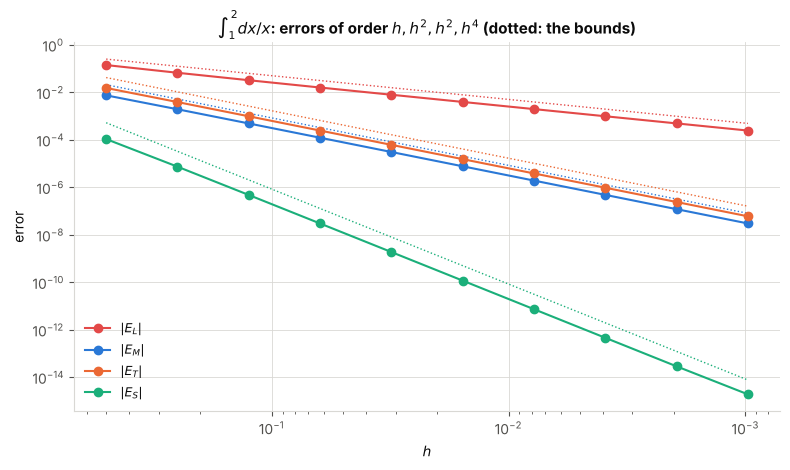

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

f = lambda x: 1 / x                     # integral over [1, 2] is ln 2
a, b, exact = 1.0, 2.0, np.log(2)
M1, M2, M4 = 1.0, 2.0, 24.0             # max of |f'|, |f''|, |f''''| on [1, 2]

def rules(n):
    e = np.linspace(a, b, n + 1); h = (b - a) / n; m = (e[:-1] + e[1:]) / 2
    L = h * f(e[:-1]).sum(); M = h * f(m).sum(); T = h * (f(e[:-1]) + f(e[1:])).sum() / 2
    return h, L, M, T, (2 * M + T) / 3

ns = 2 ** np.arange(1, 11)
rows = [rules(n) for n in ns]
hs = np.array([r[0] for r in rows])
err = {name: np.abs(np.array([r[k] for r in rows]) - exact) for k, name in enumerate(["L", "M", "T", "S"], start=1)}
bounds = {"L": (b - a) * M1 / 2 * hs, "M": (b - a) * M2 / 24 * hs**2,
          "T": (b - a) * M2 / 12 * hs**2, "S": (b - a) * M4 / 2880 * hs**4}
print(" n   |E_L|      |E_M|      |E_T|      |E_S|      E_T/E_M")
for i, n in enumerate(ns[:6]):
    r = rules(n)
    print(f"{n:3d} {err['L'][i]:.3e}  {err['M'][i]:.3e}  {err['T'][i]:.3e}  {err['S'][i]:.3e}  {(exact - r[3]) / (exact - r[2]):.3f}")
print("all errors below their bounds:", all((err[k] <= bounds[k] * (1 + 1e-12)).all() for k in err))

fig, ax = plt.subplots(figsize=(8, 4.8))
for k, col in zip(["L", "M", "T", "S"], [RED, BLUE, ORANGE, AQUA]):
    mask = err[k] > 1e-15
    ax.loglog(hs[mask], err[k][mask], "o-", color=col, label=f"$|E_{k}|$")
    ax.loglog(hs, bounds[k], ":", color=col, lw=1)
ax.set_xlabel("$h$"); ax.set_ylabel("error"); ax.invert_xaxis(); ax.legend(fontsize=9)
ax.set_title(r"$\int_1^2 dx/x$: errors of order $h, h^2, h^2, h^4$ (dotted: the bounds)")
plt.tight_layout(); plt.show()